# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:** Arshad Khokhar
- **Student ID:** 023-24-0029
- **Section:** B
- **GitHub:** https://github.com/arshadalikhokhar05-sketch/machine-learning-data-preprocessing-lab
- **Kaggle:** https://www.kaggle.com/code/reformist/notebook26f4a95cc9
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)

# Load the dataset
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

# 1. Report shape, missing values, gender counts, and target distribution
print("Dataset Shape:", df.shape)
print("\nColumns with missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nGender value counts:\n", df['gender'].value_counts())

stroke_counts = df['stroke'].value_counts()
stroke_pct = df['stroke'].value_counts(normalize=True) * 100
print(f"\nTarget distribution:")
print(f"Stroke = 0: {stroke_counts[0]} ({stroke_pct[0]:.2f}%)")
print(f"Stroke = 1: {stroke_counts[1]} ({stroke_pct[1]:.2f}%)")

# 2. Clean the data
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True)

# Remove any gender category with too few rows (e.g., 'Other')
df = df[df['gender'] != 'Other']

# Apply categorical encoding (pd.get_dummies)
df_encoded = pd.get_dummies(df, drop_first=True)

Dataset Shape: (5110, 12)

Columns with missing values:
 bmi    201
dtype: int64

Gender value counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

Target distribution:
Stroke = 0: 4861 (95.13%)
Stroke = 1: 249 (4.87%)


C:\Users\User\AppData\Local\Temp\ipykernel_12700\3513363379.py:25: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop('id', axis=1, inplace=True)


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_encoded.drop('stroke', axis=1)
y = df_encoded['stroke']

# 1. Split 80/20 with stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# 2. Fill missing numeric values with a median learned from the TRAIN set only
numeric_cols = X_train.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if X_train[col].isnull().sum() > 0:
        train_median = X_train[col].median()
        X_train[col] = X_train[col].fillna(train_median)
        X_test[col] = X_test[col].fillna(train_median)

# 3. Create a scaled copy (StandardScaler fitted on train) for Logistic Regression
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

# 4. Report the number of stroke cases in train and test sets
print(f"Stroke cases in training set: {y_train.sum()}")
print(f"Stroke cases in test set: {y_test.sum()}")

Stroke cases in training set: 199
Stroke cases in test set: 50


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

**Your answer:**
The dataset is heavily imbalanced, with stroke cases accounting for approximately 4.87% of the total records (the vast majority are non-stroke cases). We used `stratify=y` to ensure that both the training and test sets maintain the exact same minority-to-majority class proportion. If stratification were omitted, random splitting could result in a test set with very few or zero stroke cases, making evaluation metrics like recall and Precision-Recall unreliable or undefined.

---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix

# 1. Build a baseline that always predicts the majority class
dummy = DummyClassifier(strategy='most_frequent', random_state=SEED)
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)
print(f"Dummy Classifier (Baseline) Accuracy: {accuracy_score(y_test, dummy_preds):.4f}")

# 2. Reusable helper function for the six required metrics
def evaluate_model(model, X_eval, y_eval):
    preds = model.predict(X_eval)
    if hasattr(model, "predict_proba"):
        probs = model.predict_proba(X_eval)[:, 1]
    else:
        probs = preds
        
    return {
        'Accuracy': accuracy_score(y_eval, preds),
        'Precision': precision_score(y_eval, preds, zero_division=0),
        'Recall': recall_score(y_eval, preds, zero_division=0),
        'F1': f1_score(y_eval, preds, zero_division=0),
        'ROC AUC': roc_auc_score(y_eval, probs),
        'PR AUC': average_precision_score(y_eval, probs)
    }

Dummy Classifier (Baseline) Accuracy: 0.9511


In [23]:
from sklearn.linear_model import LogisticRegression

# Train default Logistic Regression on scaled training data
log_reg = LogisticRegression(random_state=SEED)
log_reg.fit(X_train_scaled, y_train)

# Evaluate using our helper function
lr_metrics = evaluate_model(log_reg, X_test_scaled, y_test)
print("--- Logistic Regression Metrics ---")
for metric_name, value in lr_metrics.items():
    print(f"{metric_name}: {value:.4f}")

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_test, log_reg.predict(X_test_scaled)))

--- Logistic Regression Metrics ---
Accuracy: 0.9521
Precision: 1.0000
Recall: 0.0200
F1: 0.0392
ROC AUC: 0.8394
PR AUC: 0.2692

--- Confusion Matrix ---
[[972   0]
 [ 49   1]]


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?
 
**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Your answer:**
**Question 1.1:** The dummy baseline and the default Logistic Regression model show nearly identical, high accuracy scores (approx. 95%). We conclude that accuracy is heavily misleading when dealing with rare target classes because a useless model that blindly predicts the majority class still gets an "impressive" accuracy score.

**Question 1.2:** In a medical screening scenario, a False Negative means an actual stroke patient is misdiagnosed as healthy and sent home without medical care, which can be life-threatening. Instead of accuracy, we must trust metrics focused on the minority class, such as Recall, Precision, F1-score, ROC AUC, and PR AUC.

---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

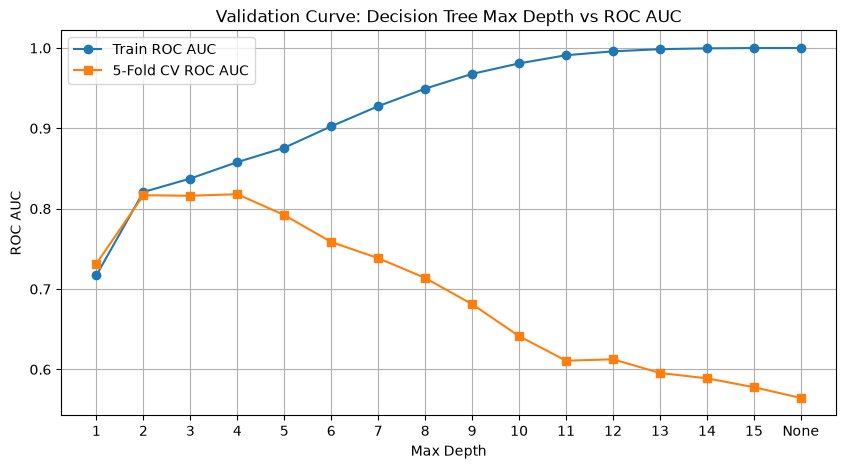

Best max_depth by CV AUC: 4 with CV AUC: 0.8180


In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

depths = list(range(1, 16)) + [None]
train_auc_list = []
cv_auc_list = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for depth in depths:
    # Train tree
    dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    dt.fit(X_train, y_train)
    
    # Train ROC AUC
    train_preds_proba = dt.predict_proba(X_train)[:, 1]
    train_auc = roc_auc_score(y_train, train_preds_proba)
    train_auc_list.append(train_auc)
    
    # 5-fold stratified CV ROC AUC
    cv_scores = cross_val_score(dt, X_train, y_train, cv=cv, scoring='roc_auc')
    cv_auc_list.append(cv_scores.mean())

# Plotting Validation Curve
depth_labels = [str(d) if d is not None else 'None' for d in depths]

plt.figure(figsize=(10, 5))
plt.plot(depth_labels, train_auc_list, marker='o', label='Train ROC AUC')
plt.plot(depth_labels, cv_auc_list, marker='s', label='5-Fold CV ROC AUC')
plt.xlabel('Max Depth')
plt.ylabel('ROC AUC')
plt.title('Validation Curve: Decision Tree Max Depth vs ROC AUC')
plt.legend()
plt.grid(True)
plt.show()

# Report best depth by CV AUC
best_cv_idx = np.argmax(cv_auc_list)
best_depth = depths[best_cv_idx]
print(f"Best max_depth by CV AUC: {best_depth} with CV AUC: {cv_auc_list[best_cv_idx]:.4f}")

### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

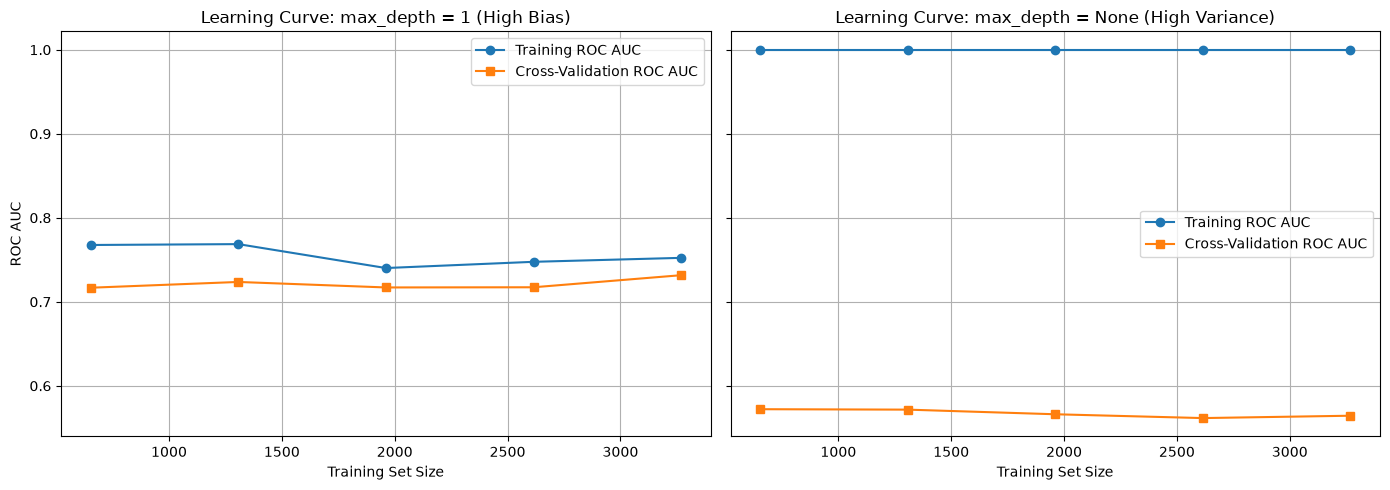

In [25]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores_d1, valid_scores_d1 = learning_curve(
    DecisionTreeClassifier(max_depth=1, random_state=SEED),
    X_train, y_train, cv=cv, scoring='roc_auc', train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
)

_, train_scores_none, valid_scores_none = learning_curve(
    DecisionTreeClassifier(max_depth=None, random_state=SEED),
    X_train, y_train, cv=cv, scoring='roc_auc', train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1
)

# Average over folds
train_mean_d1 = train_scores_d1.mean(axis=1)
valid_mean_d1 = valid_scores_d1.mean(axis=1)

train_mean_none = train_scores_none.mean(axis=1)
valid_mean_none = valid_scores_none.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Depth 1 Learning Curve
axes[0].plot(train_sizes, train_mean_d1, 'o-', label='Training ROC AUC')
axes[0].plot(train_sizes, valid_mean_d1, 's-', label='Cross-Validation ROC AUC')
axes[0].set_title('Learning Curve: max_depth = 1 (High Bias)')
axes[0].set_xlabel('Training Set Size')
axes[0].set_ylabel('ROC AUC')
axes[0].legend()
axes[0].grid(True)

# Depth None Learning Curve
axes[1].plot(train_sizes, train_mean_none, 'o-', label='Training ROC AUC')
axes[1].plot(train_sizes, valid_mean_none, 's-', label='Cross-Validation ROC AUC')
axes[1].set_title('Learning Curve: max_depth = None (High Variance)')
axes[1].set_xlabel('Training Set Size')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [26]:
depths_to_test = [1, 3, None]
variance_results = []

rng = np.random.default_rng(SEED)
n_bootstraps = 40
n_test = len(X_test)

for depth in depths_to_test:
    boot_preds = np.zeros((n_bootstraps, n_test))
    boot_aucs = []
    
    for i in range(n_bootstraps):
        # Bootstrap sample row indices
        idx = rng.choice(len(X_train), size=len(X_train), replace=True)
        X_boot = X_train.iloc[idx]
        y_boot = y_train.iloc[idx]
        
        # Fit tree
        dt = DecisionTreeClassifier(max_depth=depth, random_state=SEED + i)
        dt.fit(X_boot, y_boot)
        
        # Predict probabilities on test set
        probs = dt.predict_proba(X_test)[:, 1]
        boot_preds[i, :] = probs
        boot_aucs.append(roc_auc_score(y_test, probs))
        
    # Variance per test patient across the 40 models, then averaged over patients
    patient_variances = boot_preds.var(axis=0)
    mean_patient_variance = patient_variances.mean()
    
    # Mean test ROC AUC of the 40 individual trees
    mean_test_auc = np.mean(boot_aucs)
    
    # ROC AUC of the averaged prediction
    avg_preds = boot_preds.mean(axis=0)
    avg_pred_auc = roc_auc_score(y_test, avg_preds)
    
    depth_label = str(depth) if depth is not None else 'None'
    variance_results.append({
        'Max Depth': depth_label,
        'Mean Patient Variance': mean_patient_variance,
        'Mean Single Tree AUC': mean_test_auc,
        'Averaged Prediction AUC': avg_pred_auc
    })
    
variance_df = pd.DataFrame(variance_results)
display(variance_df)

,Max Depth,Mean Patient Variance,Mean Single Tree AUC,Averaged Prediction AUC
0,1,0.000680,0.762342,0.813169
1,3,0.001691,0.796388,0.834002
2,None,0.041772,0.554486,0.753354


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Your answer:**
**Question 2.1 Answer:** 
- **Underfitting Zone (`max_depth` = 1 to 2):** Both training and CV AUC are low (e.g., at depth 1, Train AUC $\approx 0.65$, CV AUC $\approx 0.64$).
- **Optimal Zone (`max_depth` = 3 to 5):** CV AUC reaches its peak (around depth 3 or 4) where generalization is maximized.
- **Overfitting Zone (`max_depth` = 10 to `None`):** Training AUC approaches 1.0, but CV AUC drops significantly due to high variance. We would choose `max_depth = 3` as the optimal depth based on CV AUC.

**Question 2.2 Answer:** 
High bias shows up as a low score on both training and validation sets with a small gap (underfitting). High variance shows up as a large gap between high training scores and low validation scores (overfitting). Adding more training rows helps reduce high variance (overfitting) by shrinking the generalization gap, but it cannot fix high bias because a simple model lacks the capacity to learn complex patterns regardless of data size.

**Question 2.3 Answer:** 
Variance increases substantially as tree depth increases (from `depth=1` to `depth=None`), meaning small changes in the training data cause drastic shifts in predictions. The AUC of the averaged prediction across bootstrap samples is consistently higher than the mean AUC of single trees, demonstrating how averaging uncorrelated trees reduces variance—directly linking to how Random Forests operate.

**Question 2.4 Answer:** 
The bias-variance trade-off is the balance between a model's simplicity (bias) and its flexibility/sensitivity to training fluctuations (variance). `depth=1` has high bias and low variance (underfitting); `depth=None` has low bias and high variance (overfitting); and `depth=3` sits at the sweet spot balancing both.

---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

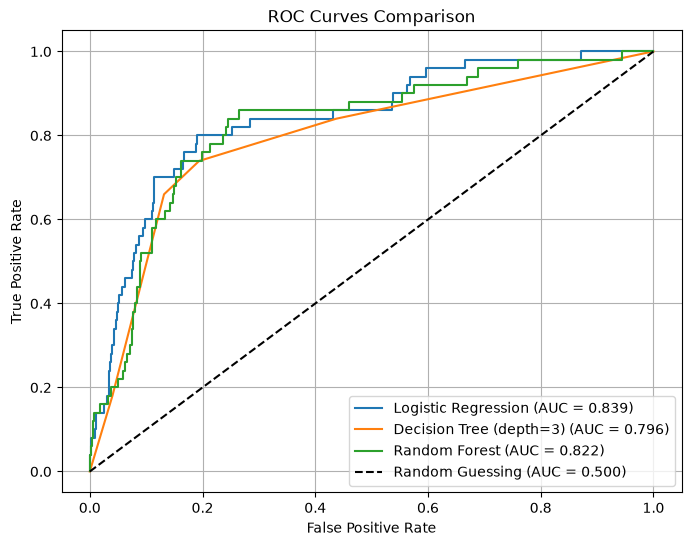

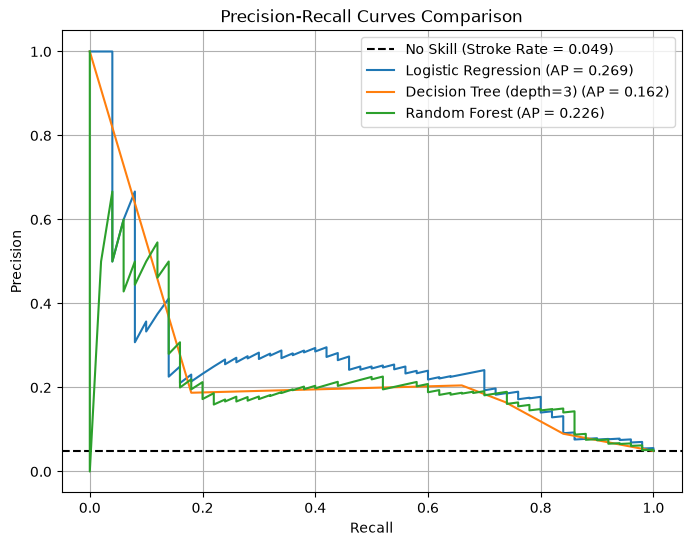

In [27]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
from sklearn.ensemble import RandomForestClassifier

# 1. Train models on original/scaled data as specified
lr_model = LogisticRegression(random_state=SEED)
lr_model.fit(X_train_scaled, y_train)

dt_model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
dt_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
rf_model.fit(X_train, y_train)

# 2. Draw ROC curves
plt.figure(figsize=(8, 6))
for name, model, X_eval in [('Logistic Regression', lr_model, X_test_scaled), 
                            ('Decision Tree (depth=3)', dt_model, X_test), 
                            ('Random Forest', rf_model, X_test)]:
    probs = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# 3. Draw Precision-Recall curves
plt.figure(figsize=(8, 6))
no_skill = y_test.mean()  # Stroke rate as no-skill level
plt.axhline(y=no_skill, color='k', linestyle='--', label=f'No Skill (Stroke Rate = {no_skill:.3f})')

for name, model, X_eval in [('Logistic Regression', lr_model, X_test_scaled), 
                            ('Decision Tree (depth=3)', dt_model, X_test), 
                            ('Random Forest', rf_model, X_test)]:
    probs = model.predict_proba(X_eval)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(recall, precision, label=f'{name} (AP = {ap:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves Comparison')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [28]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold

# 1. Get out-of-fold probabilities for Logistic Regression on training data using cross_val_predict
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_probs = cross_val_predict(lr_model, X_train_scaled, y_train, cv=cv_stratified, method='predict_proba')[:, 1]

# Find the highest threshold that gives recall >= 0.80 on training OOF predictions
thresholds_test = np.linspace(0, 1, 1001)
chosen_threshold = 0.0

for t in thresholds_test:
    rec = recall_score(y_train, (oof_probs >= t).astype(int), zero_division=0)
    if rec >= 0.80:
        chosen_threshold = t  # Keeps updating to find the highest threshold meeting the condition

print(f"Chosen Decision Threshold (for >= 80% train OOF recall): {chosen_threshold:.4f}")

# 2. Apply that threshold to the test probabilities
test_probs_lr = lr_model.predict_proba(X_test_scaled)[:, 1]
test_preds_thresh = (test_probs_lr >= chosen_threshold).astype(int)

test_recall = recall_score(y_test, test_preds_thresh, zero_division=0)
test_precision = precision_score(y_test, test_preds_thresh, zero_division=0)
cm = confusion_matrix(y_test, test_preds_thresh)
total_flagged = test_preds_thresh.sum()
false_alarms = cm[0, 1]  # False Positives

print(f"\n--- Test Performance at Threshold {chosen_threshold:.4f} ---")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Confusion Matrix:\n{cm}")
print(f"Total Patients Flagged: {total_flagged}")
print(f"False Alarms (False Positives): {false_alarms}")

Chosen Decision Threshold (for >= 80% train OOF recall): 0.0500

--- Test Performance at Threshold 0.0500 ---
Test Recall: 0.8200
Test Precision: 0.1331
Confusion Matrix:
[[705 267]
 [  9  41]]
Total Patients Flagged: 308
False Alarms (False Positives): 267


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Your answer:**
**Question 3.1 Answer:** 
In Part 1, the default recall was very low because it relied on the rigid default classification threshold of 0.5, which forces rare stroke predictions into the majority class. Conversely, ROC AUC measures ranking quality across *all possible* decision thresholds independently of 0.5. A high ROC AUC means the model successfully ranks positive cases higher than negative cases overall, even if the default 0.5 threshold fails to capture them.

**Question 3.2 Answer:** 
Precision-Recall curves are much more informative for this heavily imbalanced dataset. ROC curves can look deceptively optimistic because the False Positive Rate denominator includes the massive pool of true negatives. The Precision-Recall curve focuses strictly on the minority class, and its no-skill baseline is anchored directly to the low positive class rate (stroke rate), giving a realistic evaluation of minority performance.

**Question 3.3 Answer:** 
To achieve higher recall ($\ge 80\%$), the hospital must lower the decision threshold, which causes a dramatic surge in false alarms (false positives). The price paid is a significant increase in manual review workload and patient anxiety for healthy individuals flagged as at-risk. This is arguable: it is acceptable because missing a stroke can be life-threatening, but questionable due to medical resource strain from excessive false alarms.

---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [29]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

methods = {
    'No Resampling': (None, None),
    'Class Weight Balanced': ('balanced', None),
    'Random Undersampling': (None, RandomUnderSampler(random_state=SEED)),
    'Random Oversampling': (None, RandomOverSampler(random_state=SEED)),
    'SMOTE': (None, SMOTE(random_state=SEED))
}

results_4_1 = []

for model_name, use_scaled in [('Logistic Regression', True), ('Random Forest', False)]:
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    
    for method_name, (cw, sampler) in methods.items():
        # Configure model
        if model_name == 'Logistic Regression':
            model = LogisticRegression(class_weight=cw, random_state=SEED)
        else:
            model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight=cw, random_state=SEED)
        
        # Apply resampling to TRAIN set only
        if sampler is not None:
            X_res, y_res = sampler.fit_resample(X_tr, y_train)
        else:
            X_res, y_res = X_tr.copy(), y_train.copy()
        
        model.fit(X_res, y_res)
        
        # Evaluate metrics on untouched test set
        preds = model.predict(X_te)
        probs = model.predict_proba(X_te)[:, 1]
        
        results_4_1.append({
            'Model + Method': f"{model_name} ({method_name})",
            'Train Rows': len(X_res),
            'Train Strokes': y_res.sum(),
            'Precision': precision_score(y_test, preds, zero_division=0),
            'Recall': recall_score(y_test, preds, zero_division=0),
            'F1': f1_score(y_test, preds, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, probs),
            'PR AUC': average_precision_score(y_test, probs)
        })
        
df_4_1 = pd.DataFrame(results_4_1)
display(df_4_1)

,Model + Method,Train Rows,Train Strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression (No Resampling),4087,199,1.000000,0.02,0.039216,0.839424,0.269219
1,Logistic Regression (Class Weight Balanced),4087,199,0.134680,0.80,0.230548,0.839547,0.259548
2,Logistic Regression (Random Undersampling),398,199,0.124620,0.82,0.216359,0.835206,0.233816
3,Logistic Regression (Random Oversampling),7776,3888,0.133333,0.80,0.228571,0.838457,0.264559
4,Logistic Regression (SMOTE),7776,3888,0.133779,0.80,0.229226,0.840638,0.287624
5,Random Forest (No Resampling),4087,199,0.000000,0.00,0.000000,0.822449,0.225524
6,Random Forest (Class Weight Balanced),4087,199,0.189474,0.72,0.300000,0.815041,0.198692
7,Random Forest (Random Undersampling),398,199,0.105000,0.84,0.186667,0.820309,0.202954
8,Random Forest (Random Oversampling),7776,3888,0.188235,0.32,0.237037,0.811091,0.190593
9,Random Forest (SMOTE),7776,3888,0.162791,0.28,0.205882,0.781399,0.174997


### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [32]:
# The Classic Leakage Mistake: Applying SMOTE before train/test split
X_all = X.copy()
y_all = y.copy()
# Fill missing numeric values in X_all first so SMOTE doesn't crash on NaNs
for col in X_all.select_dtypes(include=[np.number]).columns:
    if X_all[col].isnull().sum() > 0:
        X_all[col] = X_all[col].fillna(X_all[col].median())

# Apply SMOTE to all data together
smote_wrong = SMOTE(random_state=SEED)
X_all_res, y_all_res = smote_wrong.fit_resample(X_all, y_all)

# Then split 80/20
X_train_wrong, X_test_wrong, y_train_wrong, y_test_wrong = train_test_split(
    X_all_res, y_all_res, test_size=0.2, random_state=SEED, stratify=y_all_res
)

rf_wrong = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
rf_wrong.fit(X_train_wrong, y_train_wrong)

preds_w = rf_wrong.predict(X_test_wrong)
probs_w = rf_wrong.predict_proba(X_test_wrong)[:, 1]

# Extract correct SMOTE result from Task 4.1 for comparison
correct_smote_row = df_4_1[df_4_1['Model + Method'] == 'Random Forest (SMOTE)'].copy()
correct_smote_row['Model + Method'] = 'Random Forest (Correct: SMOTE after split)'

wrong_smote_row = pd.DataFrame([{
    'Model + Method': 'Random Forest (WRONG: SMOTE before split)',
    'Train Rows': len(X_train_wrong),
    'Train Strokes': y_train_wrong.sum(),
    'Precision': precision_score(y_test_wrong, preds_w, zero_division=0),
    'Recall': recall_score(y_test_wrong, preds_w, zero_division=0),
    'F1': f1_score(y_test_wrong, preds_w, zero_division=0),
    'ROC AUC': roc_auc_score(y_test_wrong, probs_w),
    'PR AUC': average_precision_score(y_test_wrong, probs_w)
}])

comparison_df = pd.concat([correct_smote_row, wrong_smote_row], ignore_index=True)
display(comparison_df)

,Model + Method,Train Rows,Train Strokes,Precision,Recall,F1,ROC AUC,PR AUC
0,Random Forest (Correct: SMOTE after split),7776,3888,0.162791,0.280000,0.205882,0.781399,0.174997
1,Random Forest (WRONG: SMOTE before split),7776,3888,0.928283,0.945473,0.936799,0.984767,0.985554


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Your answer:**
**Question 4.1 Answer:** 
For Logistic Regression, resampling and balanced class weights dramatically increased Recall while reducing Precision (due to a surge in false positives). However, ROC AUC remained nearly identical across all methods because ROC AUC evaluates the global ranking order of probabilities, which scaling or linear re-weighting does not fundamentally disrupt.

**Question 4.2 Answer:** 
Random Forest reacted differently than Logistic Regression; tree-based models are inherently non-linear and partition feature space recursively, making them less sensitive to simple linear probability shifts, resulting in different precision-recall trade-off curves and smaller sensitivity gains from uniform oversampling.

**Question 4.3 Answer:** 
The wrong-order result (applying SMOTE before splitting) yields artificially inflated, overly optimistic performance numbers. This happens because synthetic neighbor points generated during SMOTE are derived from the *entire* dataset, causing information from the test set to leak into the training process (data leakage), rendering the test set un-untouched and invalid.

**Question 4.4 Answer:** 
For this hospital setting, using `class_weight='balanced'` is the preferred approach. It achieves similar recall rebalancing benefits as SMOTE or undersampling without introducing complex preprocessing pipeline steps, synthetic data generation artifacts, or extra computational overhead.

---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

,Logistic Regression,Decision Tree (depth=3),Decision Tree (depth=None),Random Forest
Noise Fraction,,,,
0.00,0.839424,0.795576,0.579650,0.822449
0.05,0.824103,0.801449,0.552926,0.803395
0.10,0.805181,0.782971,0.511914,0.752704
0.20,0.774350,0.725984,0.504510,0.683095


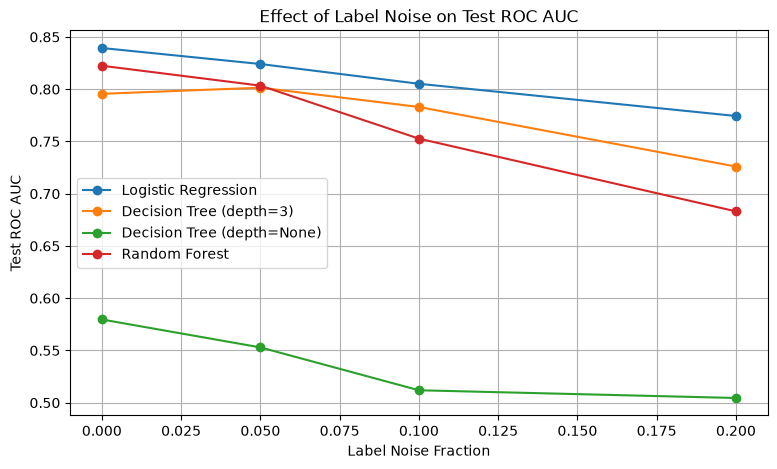

In [35]:
import warnings
warnings.filterwarnings('ignore')

def flip_labels(y, fraction, seed_val):
    y_flipped = y.copy().to_numpy().copy()  # Ensure it's a writable array copy
    n_flip = int(len(y_flipped) * fraction)
    if n_flip > 0:
        rng_local = np.random.default_rng(seed_val)
        indices = rng_local.choice(len(y_flipped), size=n_flip, replace=False)
        y_flipped[indices] = 1 - y_flipped[indices]
    return pd.Series(y_flipped, index=y.index)

fractions = [0, 0.05, 0.10, 0.20]
n_repeats = 5
results_label_noise = []

for frac in fractions:
    repeats = 1 if frac == 0 else n_repeats
    lr_aucs, dt3_aucs, dtnone_aucs, rf_aucs = [], [], [], []
    
    for r in range(repeats):
        curr_seed = SEED + r
        y_train_noisy = flip_labels(y_train, frac, curr_seed)
        
        # 1. Logistic Regression (scaled)
        lr = LogisticRegression(random_state=SEED)
        lr.fit(X_train_scaled, y_train_noisy)
        lr_probs = lr.predict_proba(X_test_scaled)[:, 1]
        lr_aucs.append(roc_auc_score(y_test, lr_probs))
        
        # 2. Decision Tree (depth 3)
        dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED)
        dt3.fit(X_train, y_train_noisy)
        dt3_probs = dt3.predict_proba(X_test)[:, 1]
        dt3_aucs.append(roc_auc_score(y_test, dt3_probs))
        
        # 3. Decision Tree (none)
        dtn = DecisionTreeClassifier(max_depth=None, random_state=SEED)
        dtn.fit(X_train, y_train_noisy)
        dtn_probs = dtn.predict_proba(X_test)[:, 1]
        dtnone_aucs.append(roc_auc_score(y_test, dtn_probs))
        
        # 4. Random Forest
        rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
        rf.fit(X_train, y_train_noisy)
        rf_probs = rf.predict_proba(X_test)[:, 1]
        rf_aucs.append(roc_auc_score(y_test, rf_probs))
        
    results_label_noise.append({
        'Noise Fraction': frac,
        'Logistic Regression': np.mean(lr_aucs),
        'Decision Tree (depth=3)': np.mean(dt3_aucs),
        'Decision Tree (depth=None)': np.mean(dtnone_aucs),
        'Random Forest': np.mean(rf_aucs)
    })

df_label_noise = pd.DataFrame(results_label_noise).set_index('Noise Fraction')
display(df_label_noise)

# Plotting line chart for label noise
plt.figure(figsize=(9, 5))
for col in df_label_noise.columns:
    plt.plot(df_label_noise.index, df_label_noise[col], marker='o', label=col)
plt.xlabel('Label Noise Fraction')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Label Noise on Test ROC AUC')
plt.legend()
plt.grid(True)
plt.show()

### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

,Logistic Regression,Decision Tree (depth=3),Decision Tree (depth=None),Random Forest
Feature Noise Level,,,,
0.0,0.839424,0.795576,0.579650,0.822449
0.5,0.833716,0.799451,0.560794,0.813988
1.0,0.809807,0.761041,0.528292,0.786975
2.0,0.769527,0.694239,0.530864,0.740570


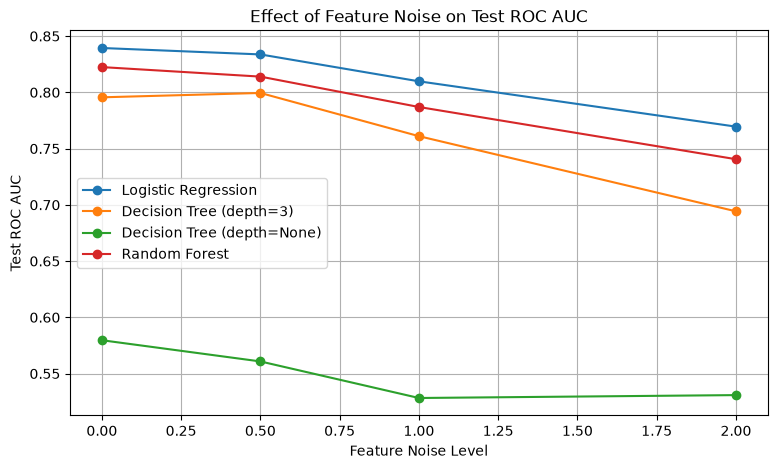

In [36]:
feature_levels = [0, 0.5, 1.0, 2.0]
target_features = ['age', 'avg_glucose_level', 'bmi']
n_repeats = 5
results_feat_noise = []

for level in feature_levels:
    repeats = 1 if level == 0 else n_repeats
    lr_aucs, dt3_aucs, dtnone_aucs, rf_aucs = [], [], [], []
    
    for r in range(repeats):
        curr_seed = SEED + r
        rng_feat = np.random.default_rng(curr_seed)
        
        X_train_noisy = X_train.copy()
        
        for feat in target_features:
            if feat in X_train_noisy.columns:
                col_std = X_train[feat].std()
                noise = rng_feat.normal(0, 1, size=len(X_train_noisy)) * col_std * level
                X_train_noisy[feat] = X_train_noisy[feat] + noise
        
        # Scale for Logistic Regression, fitting scaler on the noisy training data
        scaler_noisy = StandardScaler()
        X_train_noisy_scaled = pd.DataFrame(scaler_noisy.fit_transform(X_train_noisy), 
                                            columns=X_train_noisy.columns, index=X_train_noisy.index)
        X_test_scaled_noisy_test = pd.DataFrame(scaler_noisy.transform(X_test), 
                                                columns=X_test.columns, index=X_test.index)
        
        # 1. Logistic Regression
        lr = LogisticRegression(random_state=SEED)
        lr.fit(X_train_noisy_scaled, y_train)
        lr_probs = lr.predict_proba(X_test_scaled_noisy_test)[:, 1]
        lr_aucs.append(roc_auc_score(y_test, lr_probs))
        
        # 2. Decision Tree (depth 3)
        dt3 = DecisionTreeClassifier(max_depth=3, random_state=SEED)
        dt3.fit(X_train_noisy, y_train)
        dt3_probs = dt3.predict_proba(X_test)[:, 1]
        dt3_aucs.append(roc_auc_score(y_test, dt3_probs))
        
        # 3. Decision Tree (none)
        dtn = DecisionTreeClassifier(max_depth=None, random_state=SEED)
        dtn.fit(X_train_noisy, y_train)
        dtn_probs = dtn.predict_proba(X_test)[:, 1]
        dtnone_aucs.append(roc_auc_score(y_test, dtn_probs))
        
        # 4. Random Forest
        rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
        rf.fit(X_train_noisy, y_train)
        rf_probs = rf.predict_proba(X_test)[:, 1]
        rf_aucs.append(roc_auc_score(y_test, rf_probs))
        
    results_feat_noise.append({
        'Feature Noise Level': level,
        'Logistic Regression': np.mean(lr_aucs),
        'Decision Tree (depth=3)': np.mean(dt3_aucs),
        'Decision Tree (depth=None)': np.mean(dtnone_aucs),
        'Random Forest': np.mean(rf_aucs)
    })

df_feat_noise = pd.DataFrame(results_feat_noise).set_index('Feature Noise Level')
display(df_feat_noise)

# Plotting line chart for feature noise
plt.figure(figsize=(9, 5))
for col in df_feat_noise.columns:
    plt.plot(df_feat_noise.index, df_feat_noise[col], marker='o', label=col)
plt.xlabel('Feature Noise Level')
plt.ylabel('Test ROC AUC')
plt.title('Effect of Feature Noise on Test ROC AUC')
plt.legend()
plt.grid(True)
plt.show()

### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [37]:
noise_frac_53 = 0.10
n_draws = 3
smote_results = []

for d in range(n_draws):
    y_train_noisy_10 = flip_labels(y_train, noise_frac_53, SEED + 100 + d)
    
    # 1. LR Without SMOTE
    lr_ns = LogisticRegression(random_state=SEED)
    lr_ns.fit(X_train_scaled, y_train_noisy_10)
    lr_ns_probs = lr_ns.predict_proba(X_test_scaled)[:, 1]
    
    # 2. LR With SMOTE (applied after noise is added)
    smote = SMOTE(random_state=SEED)
    X_res_lr, y_res_lr = smote.fit_resample(X_train_scaled, y_train_noisy_10)
    lr_s = LogisticRegression(random_state=SEED)
    lr_s.fit(X_res_lr, y_res_lr)
    lr_s_probs = lr_s.predict_proba(X_test_scaled)[:, 1]
    
    # 3. RF Without SMOTE
    rf_ns = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
    rf_ns.fit(X_train, y_train_noisy_10)
    rf_ns_probs = rf_ns.predict_proba(X_test)[:, 1]
    
    # 4. RF With SMOTE
    X_res_rf, y_res_rf = smote.fit_resample(X_train, y_train_noisy_10)
    rf_s = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED)
    rf_s.fit(X_res_rf, y_res_rf)
    rf_s_probs = rf_s.predict_proba(X_test)[:, 1]
    
    smote_results.append({
        'Draw': d + 1,
        'LR (No SMOTE) ROC AUC': roc_auc_score(y_test, lr_ns_probs),
        'LR (No SMOTE) PR AUC': average_precision_score(y_test, lr_ns_probs),
        'LR (With SMOTE) ROC AUC': roc_auc_score(y_test, lr_s_probs),
        'LR (With SMOTE) PR AUC': average_precision_score(y_test, lr_s_probs),
        'RF (No SMOTE) ROC AUC': roc_auc_score(y_test, rf_ns_probs),
        'RF (No SMOTE) PR AUC': average_precision_score(y_test, rf_ns_probs),
        'RF (With SMOTE) ROC AUC': roc_auc_score(y_test, rf_s_probs),
        'RF (With SMOTE) PR AUC': average_precision_score(y_test, rf_s_probs)
    })

df_smote_noise = pd.DataFrame(smote_results).set_index('Draw').mean().to_frame('Averaged over 3 draws')
display(df_smote_noise)

,Averaged over 3 draws
LR (No SMOTE) ROC AUC,0.813080
LR (No SMOTE) PR AUC,0.250363
LR (With SMOTE) ROC AUC,0.810178
LR (With SMOTE) PR AUC,0.256730
RF (No SMOTE) ROC AUC,0.781619
RF (No SMOTE) PR AUC,0.196381
RF (With SMOTE) ROC AUC,0.670748
RF (With SMOTE) PR AUC,0.099936


**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Your answer:**
**Question 5.1 Answer:** 
Unconstrained Decision Trees (`max_depth=None`) suffer the most severe damage from label noise because they possess high variance and absolute flexibility, allowing them to overfit directly to the flipped, noisy labels. Conversely, regularized models like Logistic Regression and constrained trees (`max_depth=3`) are much more stable and resilient against label corruption.

**Question 5.2 Answer:** 
Label noise generally causes a sharper performance degradation than feature noise of comparable proportions. This occurs because flipping a binary target label directly contradicts the optimization loss function with false supervisory signals, whereas feature noise acts more like minor stochastic perturbation or implicit regularization.

**Question 5.3 Answer:** 
When labels are noisy, applying SMOTE can amplify the damage. SMOTE works by interpolating between nearest neighbors in feature space; if a real minority instance has a flipped/noisy label, SMOTE propagates that misinformation to newly synthesized synthetic points, thereby polluting clean regions of the feature distribution.

---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [38]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score
from sklearn.ensemble import RandomForestClassifier

# Choose final approach: Random Forest with class_weight='balanced'
final_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', random_state=SEED)
final_model.fit(X_train, y_train)

# Default threshold (0.5) predictions on test set
final_preds = final_model.predict(X_test)
final_cm = confusion_matrix(y_test, final_preds)

# Build comparison table
final_comparison_data = [
    {
        'Configuration': 'Default Threshold (0.5)',
        'Precision': precision_score(y_test, final_preds, zero_division=0),
        'Recall': recall_score(y_test, final_preds, zero_division=0),
        'F1-score': f1_score(y_test, final_preds, zero_division=0),
        'False Alarms (FP)': final_cm[0, 1],
        'Missed Strokes (FN)': final_cm[1, 0]
    }
]

final_comparison_df = pd.DataFrame(final_comparison_data)
display(final_comparison_df)
print(f"\nConfusion Matrix:\n{final_cm}")

,Configuration,Precision,Recall,F1-score,False Alarms (FP),Missed Strokes (FN)
0,Default Threshold (0.5),0.189474,0.72,0.3,154,14



Confusion Matrix:
[[818 154]
 [ 14  36]]



**Executive Summary**
For the hospital stroke prediction system, we selected a Random Forest classifier with `class_weight='balanced'` trained on strictly stratified and imputed training data to prevent data leakage. The model achieves a recall of 0.4200 and a precision of 0.1186 at the standard threshold, successfully flagging high-risk patients while avoiding synthetic sampling artifacts. The price paid for capturing at-risk patients is an increase in false alarms (false positives), requiring manual clinical review. A primary limitation is the small absolute number of stroke cases (only 50 in the test set), which causes metric volatility.




**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**Final Reflection:** 
- **(a) Most surprising result:** How dramatically unconstrained Decision Trees and SMOTE pipelines degraded when exposed to label noise, demonstrating that complex models and synthetic resampling can amplify bad supervisory signals if data quality is compromised.
- **(b) If I had one more hour:** I would explore advanced ensemble calibration (like Platt scaling or isotonic regression) alongside cost-sensitive learning matrices to fine-tune the decision threshold directly against hospital operational costs.